In [8]:
import xarray as xr
from regional_mom6 import regridding as rgd
import xesmf as xe

In [14]:
hgrid = xr.open_dataset("replica_grid.nc")
t_points = rgd.get_hgrid_arakawa_c_points(hgrid)
t_points["lon"] = t_points.tlon
t_points["lat"] = t_points.tlat
t_points.lat.min()

<xarray.DataArray 'lat' ()>
array(52.44655262)

In [19]:
bathy = xr.open_dataset("/glade/derecho/scratch/manishrv/ice/croc/gebco/GEBCO_2024.nc", chunks = {})
bathy = bathy.sel(lat=slice(50, bathy.lat.max().item()))
bathy

<xarray.Dataset>
Dimensions:    (lon: 86400, lat: 9600)
Coordinates:
  * lon        (lon) float64 -180.0 -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * lat        (lat) float64 50.0 50.01 50.01 50.01 ... 89.99 89.99 89.99 90.0
Data variables:
    crs        |S1 ...
    elevation  (lat, lon) int16 dask.array<chunksize=(9600, 86400), meta=np.ndarray>
Attributes: (12/36)
    title:                           The GEBCO_2024 Grid - a continuous terra...
    summary:                         The GEBCO_2024 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_units:       meters
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    references:                      DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    node_offset:                     1.0

In [25]:
import numpy as np
extended_elevation = np.concatenate(
    [bathy.elevation.values, bathy.elevation.isel(lon=0).values[:, np.newaxis]],
    axis=1
)

In [33]:
extended_lon = np.append(bathy.lon.values, -180)


In [34]:
bathy_extended = xr.Dataset(
    {
        "elevation": (["lat", "lon"], extended_elevation)
    },
    coords={
        "lat": bathy.lat,
        "lon": extended_lon
    }
)
bathy_extended

<xarray.Dataset>
Dimensions:    (lat: 9600, lon: 86401)
Coordinates:
  * lat        (lat) float64 50.0 50.01 50.01 50.01 ... 89.99 89.99 89.99 90.0
  * lon        (lon) float64 -180.0 -180.0 -180.0 -180.0 ... 180.0 180.0 -180.0
Data variables:
    elevation  (lat, lon) int16 -5512 -5507 -5509 -5514 ... -4223 -4222 -4175

In [35]:
regridded_bathy = bathy_extended.interp(lat=t_points.tlat,lon = t_points.tlon)

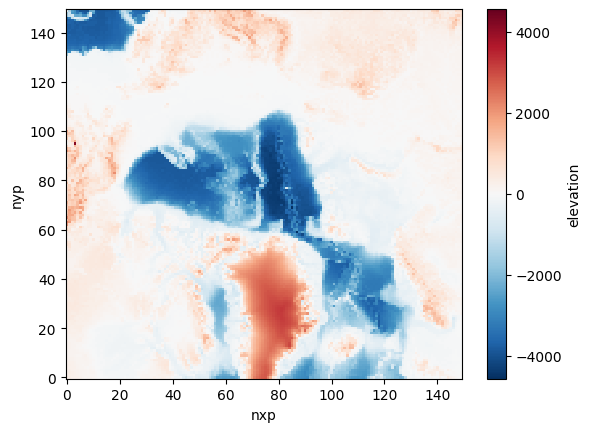

In [36]:
regridded_bathy.elevation.plot()

In [37]:
regridded_bathy.to_netcdf("regridding_gebco_bathy.nc")